# Uplift Modeling: Who to Target with Ads

## Imports

In [1]:
import sys

sys.path.append("..")
%load_ext autoreload
%autoreload 2

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import sklearn.utils
from sklearn.utils._optional_dependencies import check_matplotlib_support
sklearn.utils.check_matplotlib_support = check_matplotlib_support
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklift.metrics import qini_auc_score, uplift_at_k
from sklift.viz import plot_qini_curve

rng = np.random.default_rng(52)

## Train / Validation / Test Split

In [2]:
df = duckdb.sql("SELECT * FROM '../data/criteo.parquet' USING SAMPLE bernoulli(50%) REPEATABLE (52)").df()

train, val, test = (lambda x: [x[0], *train_test_split(x[1], test_size=0.5, stratify=x[1]['treatment'], random_state=52)])(train_test_split(df, test_size=0.3, stratify=df['treatment'], random_state = 52))
train_tr, val_tr = train[train['treatment'] == 1], val[val['treatment'] == 1]
train_ct, val_ct = train[train['treatment'] == 0], val[val['treatment'] == 0]

features = [f'f{i}' for i in range(12)]
X_train_tr, Y_train_tr, X_val_tr, Y_val_tr = train_tr[features], train_tr['conversion'], val_tr[features], val_tr['conversion']
X_train_ct, Y_train_ct, X_val_ct, Y_val_ct = train_ct[features], train_ct['conversion'], val_ct[features], val_ct['conversion']
X_test, Y_test = test[features], test['conversion']

## T-learner


### CatBoost model for treatment group


In [3]:
model_tr = CatBoostClassifier(
    iterations=1000,
    eval_metric="Logloss",
    early_stopping_rounds=50,
    random_seed=52,
    verbose=100,
)

model_tr.fit(X_train_tr, Y_train_tr, eval_set=(X_val_tr, Y_val_tr))
model_tr.get_best_iteration()

Learning rate set to 0.248209
0:	learn: 0.1945596	test: 0.1946452	best: 0.1946452 (0)	total: 281ms	remaining: 4m 40s
100:	learn: 0.0120692	test: 0.0124061	best: 0.0124053 (99)	total: 28s	remaining: 4m 9s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.01239733519
bestIteration = 113

Shrink model to first 114 iterations.


113

### CatBoost model for control group

In [4]:
model_сt = CatBoostClassifier(
    iterations=1000,
    eval_metric="Logloss",
    early_stopping_rounds=50,
    random_seed=52,
    verbose=100,
)

model_сt.fit(X_train_ct, Y_train_ct, eval_set=(X_val_ct, Y_val_ct))
model_сt.get_best_iteration()

Learning rate set to 0.161737
0:	learn: 0.2662779	test: 0.2662323	best: 0.2662323 (0)	total: 40.9ms	remaining: 40.8s
100:	learn: 0.0074435	test: 0.0083653	best: 0.0083391 (63)	total: 5.85s	remaining: 52.1s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.008339143149
bestIteration = 63

Shrink model to first 64 iterations.


63

### Average Uplift

In [5]:
pred_tr = model_tr.predict_proba(X_test)[:, 1]
pred_ct = model_сt.predict_proba(X_test)[:, 1]
uplift = pred_tr - pred_ct

np.average(uplift)

np.float64(0.001083071934027161)

### Uplift by Decile

In [6]:
test["uplift"] = pred_tr - pred_ct

duckdb.sql("""
WITH t AS(
    SELECT *, NTILE(10) OVER (ORDER BY uplift DESC) as decile
    FROM test
)
SELECT decile,
    CAST(AVG(uplift) AS DECIMAL(10, 6)) expected_uplift,
    CAST(AVG(CASE WHEN treatment = 1 THEN conversion END) AS DECIMAL(10, 6)) conversion_treatment,
    CAST(AVG(CASE WHEN treatment = 0 THEN conversion END) AS DECIMAL(10, 6)) conversion_control,
    CAST(conversion_treatment - conversion_control AS DECIMAL(10, 6)) actual_uplift
FROM t
GROUP BY decile
ORDER BY decile
""")

┌────────┬─────────────────┬──────────────────────┬────────────────────┬───────────────┐
│ decile │ expected_uplift │ conversion_treatment │ conversion_control │ actual_uplift │
│ int64  │  decimal(10,6)  │    decimal(10,6)     │   decimal(10,6)    │ decimal(10,6) │
├────────┼─────────────────┼──────────────────────┼────────────────────┼───────────────┤
│      1 │        0.011188 │             0.022855 │           0.015191 │      0.007664 │
│      2 │        0.000586 │             0.001804 │           0.001280 │      0.000524 │
│      3 │        0.000147 │             0.000551 │           0.000375 │      0.000176 │
│      4 │        0.000062 │             0.000439 │           0.000313 │      0.000126 │
│      5 │        0.000020 │             0.000124 │           0.000062 │      0.000062 │
│      6 │        0.000005 │             0.000056 │           0.000062 │     -0.000006 │
│      7 │       -0.000013 │             0.000180 │           0.000000 │      0.000180 │
│      8 │       -0.0

## Qini Curve & Uplift@k: T-learner vs Baseline

T-learner: qini=0.1581, uplift@10%=0.00766, uplift@30%=0.00320
baseline: qini=0.1802, uplift@10%=0.00773, uplift@30%=0.00337


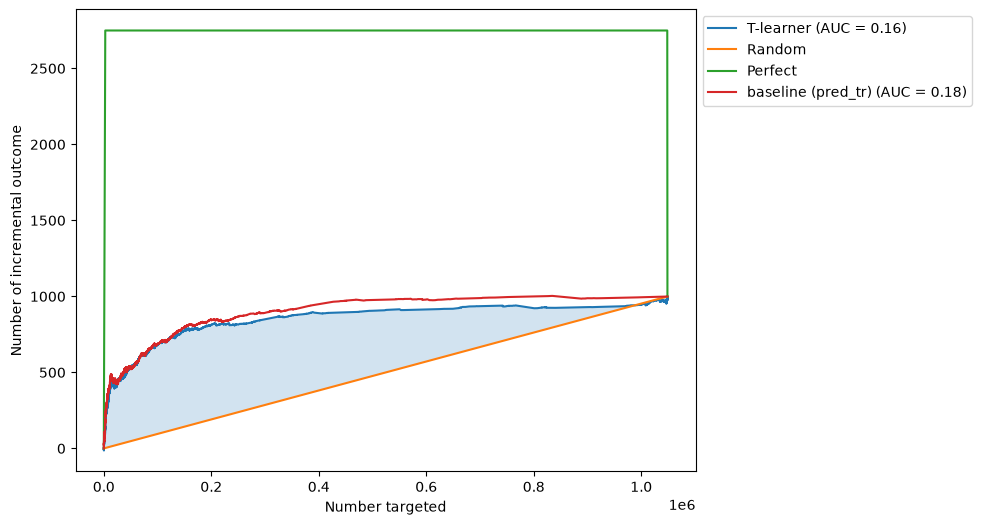

In [8]:
for name, score in [("T-learner", test["uplift"]), ("baseline", pred_tr)]:
    qini = qini_auc_score(test["conversion"], score, test["treatment"])
    u10 = uplift_at_k(test["conversion"], score, test["treatment"], strategy="overall", k=0.1)
    u30 = uplift_at_k(test["conversion"], score, test["treatment"], strategy="overall", k=0.3)
    print(f"{name}: qini={qini:.4f}, uplift@10%={u10:.5f}, uplift@30%={u30:.5f}")

fig, ax = plt.subplots(figsize=(8, 6))
plot_qini_curve(test["conversion"], test["uplift"], test["treatment"], ax=ax, name="T-learner")
plot_qini_curve(test["conversion"], pred_tr, test["treatment"], ax=ax, name="baseline (pred_tr)",
                random=False, perfect=False)
plt.savefig("../images/qini.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

- **Sanity check:** the average predicted uplift (0.00108) is close to the A/B effect (0.00115),
  so predictions are calibrated on average. Ranking quality is evaluated with deciles and Qini.
- **Deciles:** the effect is concentrated in the top decile (actual uplift 0.0077, ~7× the overall 0.00115).
  Decile 10 is misranked: predicted uplift is negative (−0.0011), but the actual uplift is +0.0008,
  the second highest. Users in this decile also have higher-than-average conversion without ads (0.35% vs 0.19%);
  a likely explanation is that with large predicted probabilities, small errors in the control model flip the sign of the difference.
- **Qini:** the baseline (ranking by the treatment model's P(conversion | ad)) is slightly ahead of the T-learner:
  Qini 0.18 vs 0.16, uplift@10% almost equal (0.0077). The curves match almost exactly, including small fluctuations,
  over the first ~20%: both models put largely the same users at the top. With 25% of the data the gap was larger
  (0.20 vs 0.12), so the T-learner was mainly limited by noise in the control model.
- **Business:** targeting the top 10% captures about two thirds of all incremental conversions with 10% of impressions;
  the exact threshold depends on impression cost vs conversion value.